<a href="https://colab.research.google.com/github/Khadeeja-beevi12/Mathematics-for-Data-Science/blob/main/Mathematics_for_Data_Science.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

###Mathematics for Data Science

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files

# Upload the wine quality CSV file
uploaded = files.upload()

# Read the uploaded dataset
file_name = next(iter(uploaded))
df = pd.read_csv(file_name, sep=None, engine="python")

# Display the first five rows
print(df.head())

# Display dataset shape
print("Dataset shape:", df.shape)

# Display column names
print("\nColumn names:")
print(df.columns.tolist())


Saving winequality-red.csv to winequality-red.csv
   fixed acidity  volatile acidity  citric acid  residual sugar  chlorides  \
0            7.4              0.70         0.00             1.9      0.076   
1            7.8              0.88         0.00             2.6      0.098   
2            7.8              0.76         0.04             2.3      0.092   
3           11.2              0.28         0.56             1.9      0.075   
4            7.4              0.70         0.00             1.9      0.076   

   free sulfur dioxide  total sulfur dioxide  density    pH  sulphates  \
0                 11.0                  34.0   0.9978  3.51       0.56   
1                 25.0                  67.0   0.9968  3.20       0.68   
2                 15.0                  54.0   0.9970  3.26       0.65   
3                 17.0                  60.0   0.9980  3.16       0.58   
4                 11.0                  34.0   0.9978  3.51       0.56   

   alcohol  quality  
0      9.4    

###1.
Handle missing values

In [2]:
# Check missing values before handling them
print("Missing values before cleaning:")
print(df.isnull().sum())

# Replace missing values with the mean of each column
df = df.fillna(df.mean(numeric_only=True))

# Check missing values after cleaning
print("\nMissing values after cleaning:")
print(df.isnull().sum())


Missing values before cleaning:
fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
dtype: int64

Missing values after cleaning:
fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
dtype: int64


###2.
Extract vectors

In [3]:
# Extract alcohol and citric acid as vectors
alcohol = df["alcohol"].to_numpy()
citric_acid = df["citric acid"].to_numpy()

print("Alcohol vector:")
print(alcohol)

print("\nCitric Acid vector:")
print(citric_acid)

# Display vector dimensions
print("\nAlcohol vector shape:", alcohol.shape)
print("Citric Acid vector shape:", citric_acid.shape)


Alcohol vector:
[ 9.4  9.8  9.8 ... 11.  10.2 11. ]

Citric Acid vector:
[0.   0.   0.04 ... 0.13 0.12 0.47]

Alcohol vector shape: (1599,)
Citric Acid vector shape: (1599,)


###3.
Calculate the covariance matrix

In [5]:
# Select two features
X = df[["alcohol", "density"]].to_numpy()

# Calculate the covariance matrix
cov_matrix = np.cov(X.T)

print("Covariance Matrix:")
print(cov_matrix)



Covariance Matrix:
[[ 1.13564740e+00 -9.97951790e-04]
 [-9.97951790e-04  3.56202945e-06]]


###4.
Eigenvalues and eigenvectors

In [6]:
# Calculate eigenvalues and eigenvectors
eigenvalues, eigenvectors = np.linalg.eigh(cov_matrix)

# Sort eigenvalues in descending order
indices = np.argsort(eigenvalues)[::-1]

eigenvalues = eigenvalues[indices]
eigenvectors = eigenvectors[:, indices]

# Display the top two eigenvalues
print("Top 2 Eigenvalues:")
print(eigenvalues[:2])

# Display the corresponding eigenvectors
print("\nCorresponding Eigenvectors:")
print(eigenvectors[:, :2])


Top 2 Eigenvalues:
[1.13564827e+00 2.68507580e-06]

Corresponding Eigenvectors:
[[-9.99999614e-01 -8.78753184e-04]
 [ 8.78753184e-04 -9.99999614e-01]]


###5.
Analyze wine quality

Wine Quality Distribution:
quality
3     10
4     53
5    681
6    638
7    199
8     18
Name: count, dtype: int64

Most common wine quality: 5
Number of wines with this quality: 681
Probability of the most common quality: 0.425891181988743
Percentage: 42.59 %


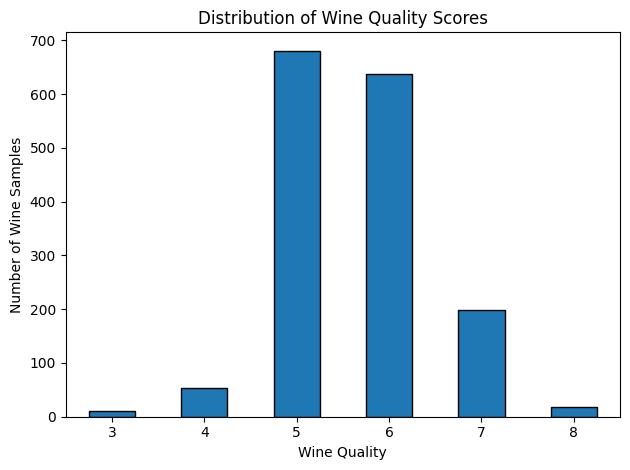

In [7]:
# Count each wine quality score
quality_counts = df["quality"].value_counts().sort_index()

print("Wine Quality Distribution:")
print(quality_counts)

# Find the most common quality score
most_common_quality = df["quality"].mode()[0]
most_common_count = int(quality_counts[most_common_quality])

print("\nMost common wine quality:", most_common_quality)
print("Number of wines with this quality:", most_common_count)

# Calculate the probability of the most common quality
probability = most_common_count / len(df)

print("Probability of the most common quality:", probability)
print("Percentage:", round(probability * 100, 2), "%")

# Plot the distribution
quality_counts.plot(kind="bar", edgecolor="black")
plt.title("Distribution of Wine Quality Scores")
plt.xlabel("Wine Quality")
plt.ylabel("Number of Wine Samples")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()
